# P3 模型選擇與實驗結果

模型候選、validation protocol、hyperparameter tuning、baselines、model comparison、feature ablation，以及模型選擇理由。

## Final Model（已在查看 Final Test 前固定）

推薦使用 **Elastic Net + QualityArea interaction + log1p target**：

- `alpha = 0.0031622776601683794`
- `l1_ratio = 0.1`
- QualityArea = OverallQual × GrLivArea，並保留兩個 main effects
- 預測後以 `expm1` 還原美元，再計算 MAE、RMSE、R²

這個選擇不是因為它在單一指標排名第一，而是綜合資料結構、模型行為與 validation 結果。

## 為什麼選 Elastic Net

### 1. 資料有明確共線性，OLS 不適合作為最終模型

完成 one-hot 後，每折約有 207–213 個模型輸入；含截距的設計矩陣平均缺少 22.6 個秩。面積、房間、地下室與車庫變數也存在高度相關。OLS 只能作無正則化參考，因其係數解不唯一，數值預測曾出現不穩定，不能作主要模型或逐係數獨立解釋。

### 2. Ridge 符合共線性需求，但不做特徵縮減

Ridge 的 L2 懲罰會同時縮小相關特徵、保留全部欄位，跨折係數結構穩定；但平均保留 209.8 個非零係數，沒有處理大量 one-hot 與弱特徵造成的模型複雜度。其 H1 組 MAE 為 13,450.27 ± 805.40 USD。

### 3. Lasso 最低 MAE，但單靠最低分數不足以選它

Lasso 的 H1 組 MAE 最低，為 13,360.81 ± 763.16 USD；但只比 Elastic Net 少 5.25 USD（0.039%），遠小於約 763–809 USD 的折間波動。Lasso 在高度相關的特徵群中可能任意保留其中一個，使選擇與係數對抽樣較敏感。

### 4. Elastic Net 同時符合相關特徵與弱特徵的資料特性

Elastic Net 結合 L1 與 L2。CV 選出的 `l1_ratio=0.1` 表示以 L2 為主，保留相關特徵群的資訊，同時用少量 L1 移除部分弱特徵。它平均保留 113.4/209.8 個非零係數；跨折標準化係數的平均 cosine similarity 為 0.960，略高於 Lasso 的 0.954。

Elastic Net 的 MAE為 13,366.06 ± 809.27 USD，與 Lasso 實質相同；RMSE為 19,925.10 USD，略低於 Lasso 的 19,945.95 USD；R²也略高，因此它在不犧牲實際預測表現的情況下，更符合本資料的共線性與高維稀疏結構。

## 模型比較證據

| 模型 | CV MAE USD ± SD | CV RMSE USD ± SD | R² | 平均非零係數 | 跨折係數 cosine |
|---|---:|---:|---:|---:|---:|
| Ridge | 13,450.27 ± 805.40 | 20,177.30 ± 2,298.49 | 0.9317 | 209.8 | 0.961 |
| Lasso | 13,360.81 ± 763.16 | 19,945.95 ± 2,265.00 | 0.9332 | 107.8 | 0.954 |
| **Elastic Net** | **13,366.06 ± 809.27** | **19,925.10 ± 2,274.15** | **0.9334** | **113.4** | **0.960** |

這些數字來自相同五折、相同 H1 feature set 與相同 target。SD 是折間標準差，不是信賴區間。模型、特徵、參數與 MAE threshold 均在查看 Final Test 前固定；Final Test 沒有用來改選模型。

## 已完成的內容

- 三層 baseline：training mean、GrLivArea 單特徵 OLS、Random Forest。
- 線性候選：OLS、Ridge、Lasso、Elastic Net，以及 QualityArea interaction model。
- 原始與 log1p target 比較，所有誤差統一以美元計算。
- 固定五折 CV、相同 folds、fold-local preprocessing、hyperparameter search。
- Raw、MI Top-15/20、Pearson Top-20、Engineered 與 H1–H3 ablation。
- 每折結果、OOF 預測、調參表、特徵入選、編碼維度、切片分析與警告檢查。
- 完整 training 重訓、唯一一次 Final Test、正式係數 CI/p/VIF、差異檢定與最大誤差案例。

## Final Test 與完整結論

事前 MAE threshold 固定為 15,000 USD，來源是 Training CV mean + 2 SD = 14,984.60 USD 後向上取整。使用完整 Training Data 重訓後，對封存的 292 筆 Final Test 評估一次。

| 模型 | Test MAE USD | Test RMSE USD | Test R² |
|---|---:|---:|---:|
| Mean | 62,580.40 | 87,619.50 | -0.0009 |
| Single-feature OLS | 38,473.84 | 57,594.46 | 0.5675 |
| Random Forest | 16,383.85 | 27,017.93 | 0.9048 |
| **Elastic Net** | **14,422.74** | **22,340.04** | **0.9349** |

Elastic Net 通過事前門檻。相較 Random Forest，MAE 平均改善 1,961.11 USD；final−RandomForest gap 的 paired bootstrap 95% CI 為 [-3,846.87, -399.02]，paired permutation p=0.0170。

最大三筆誤差為 Id 899、775、1047，絕對誤差分別為 137,718.68、99,159.63、97,064.61 USD，皆為高品質且較高價住宅。高品質組的 MAE 較高，顯示模型的主要剩餘風險集中於高價／高品質市場。

係數、bootstrap 95% CI、近似 p-value 與 VIF 已輸出。大量 VIF 為 inf，且 QualityArea、GrLivArea 的 VIF 偏高，與前述 rank deficiency 和相關特徵結構一致；因此這些係數只作條件式模型診斷，不作因果解釋。


,model,params,CV_MAE_USD_mean,CV_MAE_USD_std,CV_RMSE_USD_mean,CV_RMSE_USD_std,CV_R2_mean,CV_R2_std,mean_encoded_features,mean_rank_deficiency,mean_nonzero_coefficients,mean_nonzero_fraction,mean_pairwise_coefficient_cosine,mean_pairwise_nonzero_jaccard,median_feature_sign_consistency_when_active,MAE_gap_from_best_USD,MAE_gap_from_best_percent,recommended,recommendation_reason
0,Lasso,"{""alpha"": 0.00031622776601683794}",13360.805879,763.158892,19945.949573,2265.001744,0.933248,0.009243,209.8,22.6,107.8,0.513919,0.953817,0.665390,1.0,0.000000,0.000000,False,Comparator
1,ElasticNet,"{""alpha"": 0.0031622776601683794, ""l1_ratio"": 0.1}",13366.059101,809.274782,19925.102849,2274.151579,0.933367,0.009466,209.8,22.6,113.4,0.540556,0.960367,0.671478,1.0,5.253223,0.039318,True,L1+L2 matches correlated high-dimensional data...
2,Ridge,"{""alpha"": 10.0}",13450.266318,805.398854,20177.299314,2298.493822,0.931711,0.009251,209.8,22.6,209.8,1.000000,0.960678,0.960748,1.0,89.460440,0.669574,False,Comparator


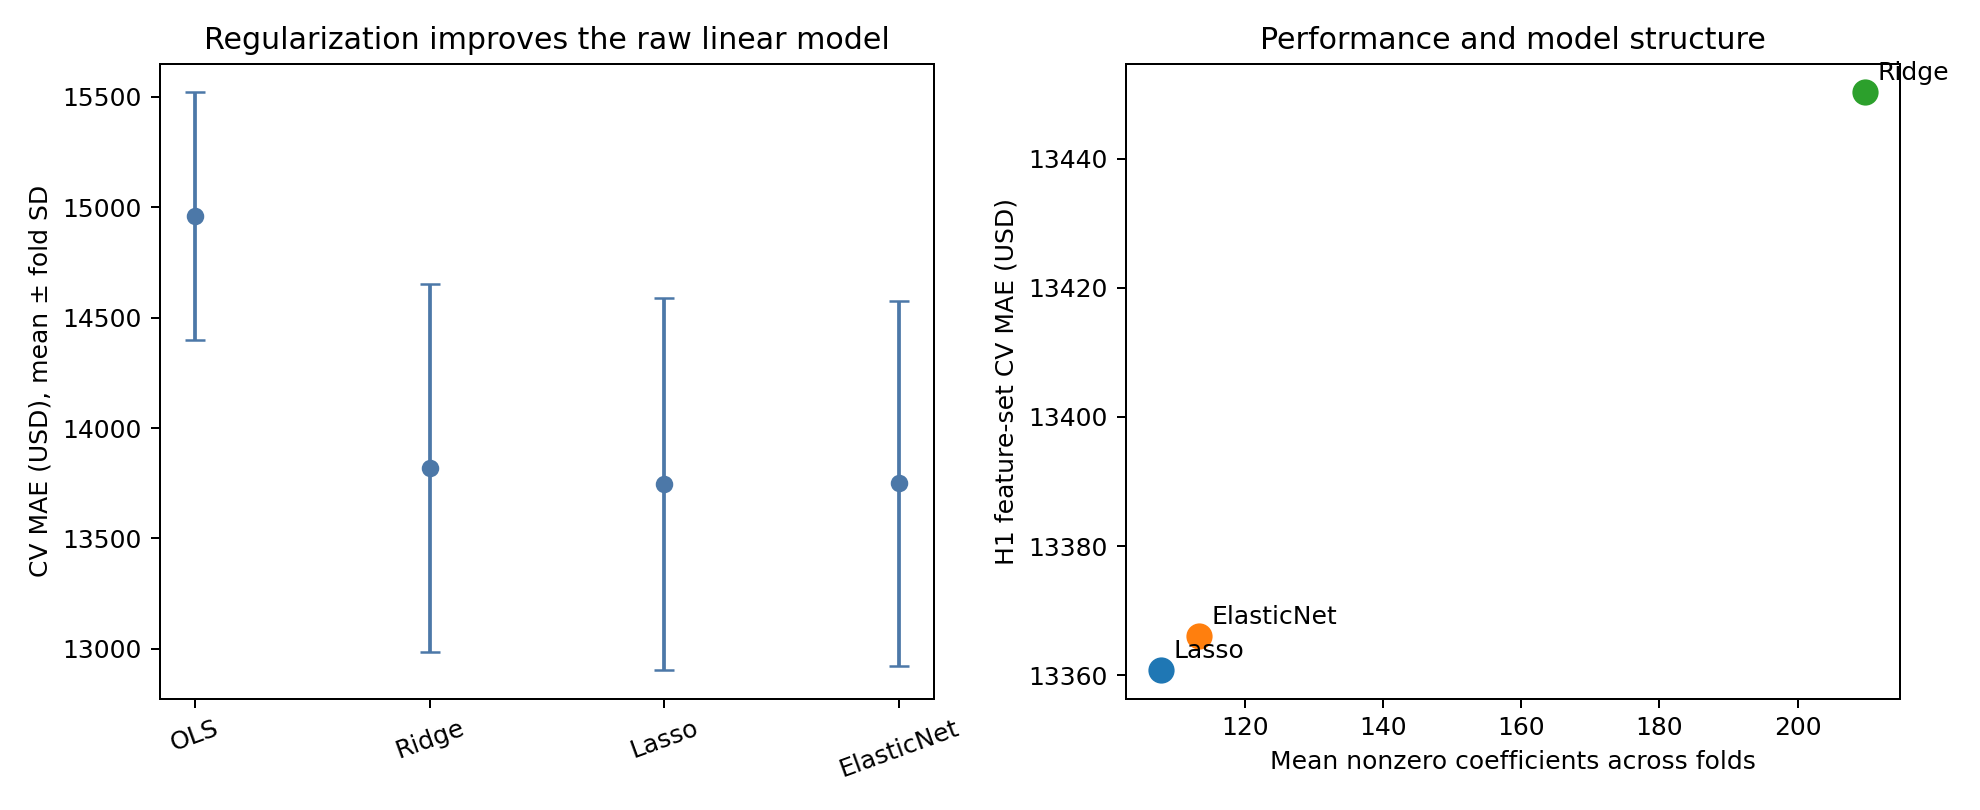

,model,target,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_RMSE_std,Test_MAE_USD,Test_RMSE_USD,Test_R2,meets_MAE_threshold
0,Mean,raw,56391.604947,1243.708910,77190.344246,4334.058636,62580.400180,87619.497667,-0.000893,False
1,SingleOLS,raw,37159.831024,2294.906008,53091.637728,2645.272119,38473.844990,57594.463066,0.567538,False
2,RandomForest,raw,16554.343986,958.099461,26107.292587,2431.402748,16383.850548,27017.929089,0.904832,False
3,ElasticNet,log1p,13366.059101,809.274782,19925.102849,2274.151579,14422.737460,22340.042901,0.934934,True


,comparison,MAE_gap_USD,CI95_low_USD,CI95_high_USD,paired_permutation_p,bootstrap_repetitions,permutation_repetitions
0,ElasticNet minus RandomForest,-1961.113088,-3846.866141,-399.024152,0.016998,5000,10000


,Id,GrLivArea,OverallQual,Neighborhood,YearBuilt,YearRemodAdd,TotalBsmtSF,GarageCars,actual_USD,predicted_USD,signed_error_USD,absolute_error_USD,cause_review
0,899,2364,9,NridgHt,2009,2010,2330,3,611657.0,473938.317166,137718.682834,137718.682834,需依房屋特徵與 training 範圍確認；原因不能只由價格猜測
1,775,1973,8,NridgHt,2006,2006,1935,3,395000.0,295840.366906,99159.633094,99159.633094,需依房屋特徵與 training 範圍確認；原因不能只由價格猜測
2,1047,2868,9,StoneBr,2005,2006,1992,3,556581.0,459516.386960,97064.613040,97064.613040,需依房屋特徵與 training 範圍確認；原因不能只由價格猜測


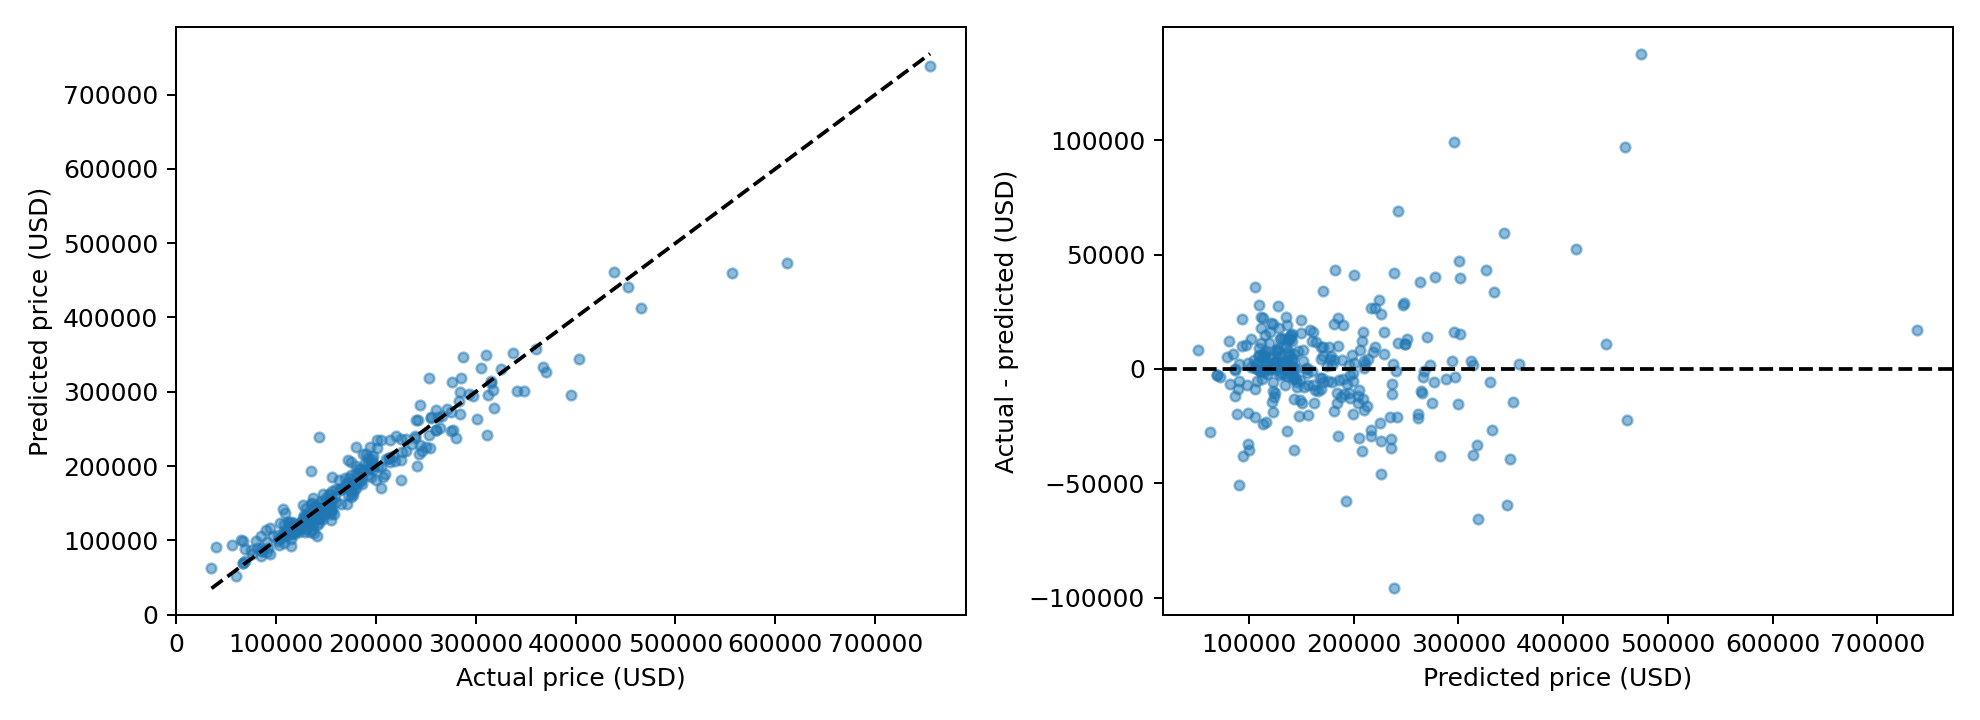

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/outputs/p1/data_split.csv').exists()), None)
assert ROOT is not None
MODEL_ROOT = ROOT / 'model'
evidence = pd.read_csv(MODEL_ROOT / 'results/tables/model_choice/model_choice_evidence.csv')
final_results = pd.read_csv(MODEL_ROOT / 'results/tables/final_test/final_test_results.csv')
significance = pd.read_csv(MODEL_ROOT / 'results/tables/final_test/model_significance.csv')
large_errors = pd.read_csv(MODEL_ROOT / 'results/tables/final_test/large_error_cases.csv')
display(evidence)
display(Image(filename=str(MODEL_ROOT / 'results/figures/model_choice/model_choice_evidence.png')))
display(final_results)
display(significance)
display(large_errors.head(3))
display(Image(filename=str(MODEL_ROOT / 'results/figures/final_test/final_predictions_residuals.png')))
